# Modelo sobre reservas_historicas

El tutor autoriza modelar con el histórico disponible. La etiqueta is_canceled incluye cancelaciones y no presentaciones. La tabla futura reservas_activas_corte_09h requiere el historial del hotel para verificar reservas activas y avisos después del corte.

El plan en docs/entregas/03_plan_modelado.md fija particiones, candidatos y selección por Average Precision en validación. El archivo ya se exploró en trabajos anteriores. La prueba aporta una evaluación retrospectiva por cohortes de llegada con esa exposición previa.

Instala las dependencias y descarga el CSV siguiendo la Entrega 02. Ejecutar todas las celdas reproduce entrenamiento, selección y evaluación.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, precision_recall_curve

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
sys.path.insert(0, str(root))
from src.modeling import run_modeling

results = run_modeling(root)
pd.DataFrame(results["bloques"]).T

,filas,positivos,prevalencia,llegada_min,llegada_max
entrenamiento,48428,17340,0.358057,2015-07-01,2016-06-29
validacion,28754,10553,0.36701,2016-07-01,2016-12-30
prueba,40687,15745,0.386979,2017-01-01,2017-08-31


Se aprende el preprocesado con entrenamiento. Las comprobaciones verifican grupos de duplicados disjuntos y cierre de etiquetas antes del siguiente bloque. Se conservan duplicados dentro de cada bloque. La cota de cierre es una aproximación offline.

El bosque y la logística tienen parámetros fijados antes de ejecutar. Se conserva el ajuste de entrenamiento del ganador para evaluar prueba.

In [2]:
pd.DataFrame(results["validacion"]).T[
    ["average_precision", "roc_auc", "cupo", "positivos_detectados", "precision_cupo", "recall_cupo"]
]

,average_precision,roc_auc,cupo,positivos_detectados,precision_cupo,recall_cupo
logistica,0.724912,0.771185,5746,4330,0.753568,0.41031
bosque,0.744384,0.787938,5746,4432,0.771319,0.419975
regla_antelacion,0.54733,0.676415,5746.0,3217.0,0.559868,0.304842


In [3]:
print("Modelo seleccionado", results["ganador"])
pd.DataFrame(results["prueba"]).T[
    ["average_precision", "roc_auc", "cupo", "positivos_detectados", "precision_cupo", "recall_cupo"]
]

Modelo seleccionado bosque


,average_precision,roc_auc,cupo,positivos_detectados,precision_cupo,recall_cupo
bosque,0.749734,0.785531,8130,6249,0.768635,0.396888
regla_antelacion,0.509347,0.655138,8130.0,4177.0,0.513776,0.265291


El cupo ilustrativo selecciona el 20% de las filas de cada mes y hotel, redondeando hacia abajo. Ambos métodos usan idéntico cupo y población. La regla prioriza mayor antelación. El modelo ordena por su score. El lote histórico incluye reservas cuyo estado activo al corte queda pendiente de reconstrucción.

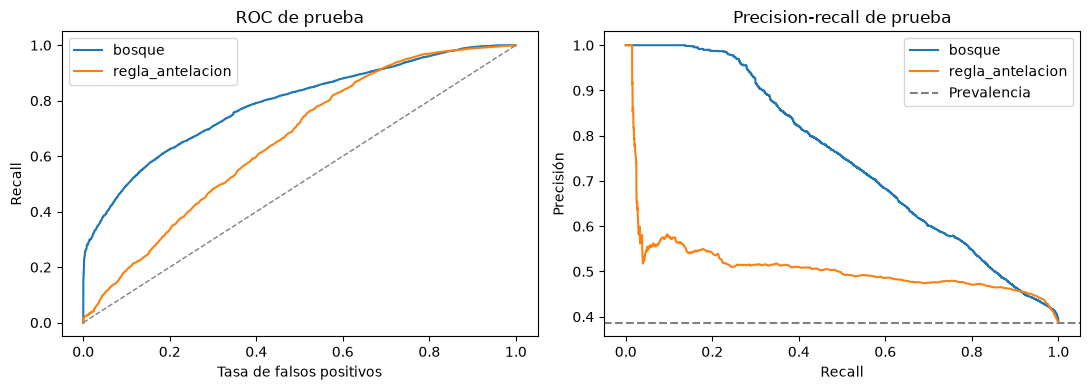

In [4]:
predictions = pd.read_csv(root / "data/processed/modelo_historico_predicciones.csv")
winner = results["ganador"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name in [winner, "regla_antelacion"]:
    scores = predictions[f"score_{name}"]
    fpr, tpr, _ = roc_curve(predictions.etiqueta, scores)
    precision, recall, _ = precision_recall_curve(predictions.etiqueta, scores)
    axes[0].plot(fpr, tpr, label=name)
    axes[1].plot(recall, precision, label=name)
axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray", linewidth=1)
axes[1].axhline(predictions.etiqueta.mean(), linestyle="--", color="gray", label="Prevalencia")
axes[0].set(xlabel="Tasa de falsos positivos", ylabel="Recall", title="ROC de prueba")
axes[1].set(xlabel="Recall", ylabel="Precisión", title="Precision-recall de prueba")
for axis in axes:
    axis.legend()
fig.tight_layout()
plt.show()

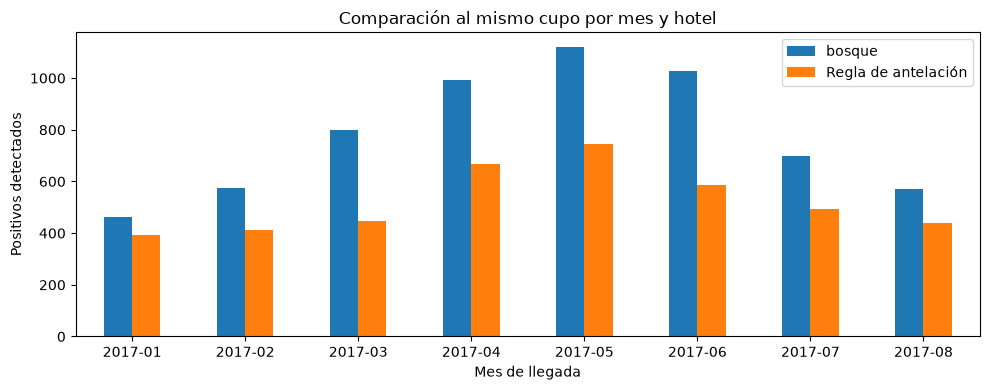

In [5]:
monthly = pd.read_csv(root / "reports/modelo_historico_mensual.csv")
counts = monthly.groupby("mes")[
    [f"detectados_{winner}", "detectados_regla_antelacion"]
].sum()
counts.columns = [winner, "Regla de antelación"]
axis = counts.plot.bar(figsize=(10, 4), rot=0)
axis.set(xlabel="Mes de llegada", ylabel="Positivos detectados", title="Comparación al mismo cupo por mes y hotel")
plt.tight_layout()
plt.show()

In [6]:
metrics = results["prueba"][winner]
rule = results["prueba"]["regla_antelacion"]
assert metrics["cupo"] == rule["cupo"]
assert predictions[f"seleccion_{winner}"].sum() == metrics["cupo"]
assert len(predictions) == results["bloques"]["prueba"]["filas"]
extra = metrics["positivos_detectados"] - rule["positivos_detectados"]
print("Positivos adicionales con el mismo cupo", extra)
print("Mejora relativa", round(100 * extra / rule["positivos_detectados"], 2), "%")
pd.Series(metrics["umbral_05"])

Positivos adicionales con el mismo cupo 2072
Mejora relativa 49.6 %


precision                              0.872803
recall                                 0.343855
f1                                     0.493348
matriz_tn_fp_fn_tp    [24153, 789, 10331, 5414]
dtype: object

La comparación mide cancelaciones o no presentaciones identificadas en el histórico. La matriz al umbral 0,5 describe otra selección cuyo tamaño depende de los scores.

Los resultados permiten comparar rankings entre cohortes históricas. Para evaluar llamadas se necesita reconstruir reservas_activas_corte_09h, verificar las variables conocidas a las nueve, definir la etiqueta de aviso posterior y realizar un piloto de contactos. El informe en docs/entregas/03_modelado_historico.md desarrolla el alcance y las limitaciones.